# Kopi Nangkau — Sales Analysis 2021–2023

**Portofolio Data Analyst** · Python · Pandas · NumPy · Matplotlib · Seaborn

---

## Latar Belakang
Kopi Nangkau adalah kedai kopi yang mencatat penjualan harian untuk 6 produk (4 minuman kopi dan 2 makanan) selama 3 tahun. Data mentah yang dicatat manual ternyata belum rapi: ada data kosong, baris ganda, dan tanggal yang terpecah di tiga kolom.

## Tujuan
1. Membersihkan data hingga siap dianalisis, dengan keputusan yang bisa dipertanggungjawabkan.
2. Memvalidasi kebijakan harga (kenaikan 2% per tahun).
3. Menjawab pertanyaan bisnis: **produk apa yang paling menguntungkan, seberapa cepat bisnis tumbuh, dan apakah ada pola musiman?**
4. Menghasilkan rekomendasi strategi yang bisa langsung dipakai pemilik usaha.

## Alur Analisis
| # | Tahap | Fokus |
|---|-------|-------|
| 1 | Data Understanding | Struktur, missing value, duplikat, masalah data |
| 2 | Data Cleaning & Preparation | Pemulihan data, tanggal, imputasi |
| 3 | Price Adjustment & Validation | Harga dasar 2021, kenaikan 2%, total penjualan |
| 4 | Exploratory Data Analysis | Produk terlaris, rata-rata harian, pola bulanan |
| 5 | Sales Performance | Pertumbuhan, outlier, tren dan musiman |
| 6 | Data Visualization | 6 visual utama |
| 7 | Business Insights | Insight, rekomendasi, kesimpulan |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

# ---- Tema visual ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlepad": 12,
})
pd.options.display.float_format = "{:,.2f}".format

WARNA_PRODUK = {
    "Americano": "#7B4B2A", "Cappuccino": "#C98B4E", "Croissant": "#E6B94B",
    "Donat": "#D9663F", "Espresso": "#2E1A12", "Latte": "#8AA68A",
}
WARNA_TAHUN = {2021: "#D2B48C", 2022: "#A0693D", 2023: "#3E2723"}
BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli",
         "Agustus", "September", "Oktober", "November", "Desember"]
BULAN_SINGKAT = [b[:3] for b in BULAN]
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

def fmt_juta(x, pos=None):
    return f"{x/1e6:,.0f}"

---
# 1️. Data Understanding
Langkah pertama: kenali data sebelum menyentuhnya. Saya mengecek ukuran, tipe data, nilai kosong, duplikat, dan sebaran nilai.

In [2]:
df_raw = pd.read_csv("../data/penjualan_kopi_2021_2023.csv", sep=";")
print(f"Jumlah baris : {df_raw.shape[0]:,}")
print(f"Jumlah kolom : {df_raw.shape[1]}")
df_raw.head(10)

Jumlah baris : 6,600
Jumlah kolom : 6


,Tahun,Bulan,Tanggal,Produk,Unit_Terjual,Harga_Per_Unit
0,2021,Januari,1,Americano,52.00,"21,000.00"
1,2021,Januari,1,Cappuccino,45.00,NaN
2,2021,Januari,1,Croissant,20.00,NaN
3,2021,Januari,1,Donat,20.00,"15,000.00"
4,2021,Januari,1,Espresso,43.00,"22,000.00"
5,2021,Januari,1,Latte,38.00,"28,000.00"
6,2021,Januari,2,Americano,44.00,"21,000.00"
7,2021,Januari,2,Cappuccino,36.00,NaN
8,2021,Januari,2,Croissant,18.00,"18,000.00"
9,2021,Januari,2,Croissant,18.00,"18,000.00"


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6600 entries, 0 to 6599
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Tahun           6600 non-null   int64  
 1   Bulan           6600 non-null   str    
 2   Tanggal         6600 non-null   int64  
 3   Produk          6100 non-null   str    
 4   Unit_Terjual    6100 non-null   float64
 5   Harga_Per_Unit  6100 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 309.5 KB


In [4]:
missing = pd.DataFrame({
    "Jumlah_Kosong": df_raw.isna().sum(),
    "Persen": df_raw.isna().mean() * 100,
})
print(f"Baris duplikat persis: {df_raw.duplicated().sum()}\n")
missing

Baris duplikat persis: 19



,Jumlah_Kosong,Persen
Tahun,0,0.00
Bulan,0,0.00
Tanggal,0,0.00
Produk,500,7.58
Unit_Terjual,500,7.58
Harga_Per_Unit,500,7.58


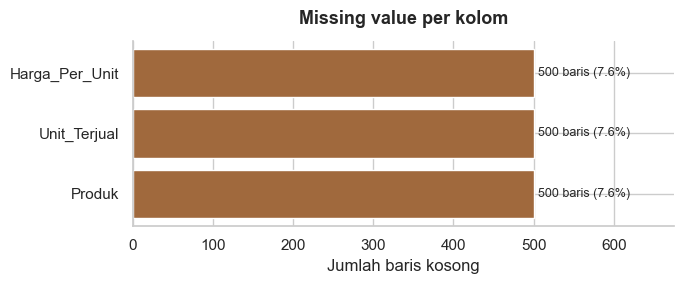

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
m = missing[missing["Jumlah_Kosong"] > 0].sort_values("Jumlah_Kosong")
ax.barh(m.index, m["Jumlah_Kosong"], color="#A0693D")
for i, v in enumerate(m["Jumlah_Kosong"]):
    ax.text(v + 5, i, f"{v} baris ({v/len(df_raw):.1%})", va="center", fontsize=9)
ax.set_xlim(0, m["Jumlah_Kosong"].max() * 1.35)
ax.set_title("Missing value per kolom")
ax.set_xlabel("Jumlah baris kosong")
plt.tight_layout()
plt.show()

In [6]:
print("Sebaran nama produk (termasuk kosong):")
display(df_raw["Produk"].value_counts(dropna=False).to_frame("Jumlah_Baris"))
print("Statistik deskriptif kolom numerik:")
display(df_raw[["Unit_Terjual", "Harga_Per_Unit"]].describe().T)
print("Jumlah baris per tahun:")
display(df_raw["Tahun"].value_counts().sort_index().to_frame("Jumlah_Baris"))

Sebaran nama produk (termasuk kosong):


,Jumlah_Baris
Produk,
Cappuccino,1024
Espresso,1022
Americano,1017
Croissant,1017
Donat,1010
Latte,1010
NaN,500


Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
Unit_Terjual,"6,100.00",33.42,11.56,0.00,25.00,35.00,42.00,71.00
Harga_Per_Unit,"6,100.00","21,964.83","4,352.20","15,000.00","18,360.00","22,000.00","25,500.00","29,120.00"


Jumlah baris per tahun:


,Jumlah_Baris
Tahun,
2021,2197
2022,2203
2023,2200


In [7]:
# Ringkasan masalah yang ditemukan
produk_kosong_harga_ada = (df_raw["Produk"].isna() & df_raw["Harga_Per_Unit"].notna()).sum()
baris_ideal = 365 * 3 * df_raw["Produk"].nunique()   # 1.095 hari x 6 produk (2021-2023 tanpa kabisat)

print("RINGKASAN MASALAH DATASET")
print("-" * 60)
print(f"1. Produk kosong              : {df_raw['Produk'].isna().sum()} baris")
print(f"   - di antaranya masih punya harga (bisa dilacak): {produk_kosong_harga_ada} baris")
print(f"2. Unit_Terjual kosong        : {df_raw['Unit_Terjual'].isna().sum()} baris")
print(f"3. Harga_Per_Unit kosong      : {df_raw['Harga_Per_Unit'].isna().sum()} baris")
print(f"4. Duplikat persis            : {df_raw.duplicated().sum()} baris")
print(f"5. Jumlah baris vs ideal      : {len(df_raw):,} vs {baris_ideal:,} (1 baris per produk per hari)")
print("6. Tanggal terpecah di 3 kolom, bulan berupa teks Indonesia")
print("7. Unit_Terjual bertipe float padahal seharusnya bilangan bulat")

RINGKASAN MASALAH DATASET
------------------------------------------------------------
1. Produk kosong              : 500 baris
   - di antaranya masih punya harga (bisa dilacak): 463 baris
2. Unit_Terjual kosong        : 500 baris
3. Harga_Per_Unit kosong      : 500 baris
4. Duplikat persis            : 19 baris
5. Jumlah baris vs ideal      : 6,600 vs 6,570 (1 baris per produk per hari)
6. Tanggal terpecah di 3 kolom, bulan berupa teks Indonesia
7. Unit_Terjual bertipe float padahal seharusnya bilangan bulat


### Temuan Awal
- Setiap kolom **Produk, Unit_Terjual, dan Harga_Per_Unit** punya sekitar **500 data kosong** (±7,6%), dan kosongnya tersebar acak di baris yang berbeda.
- Ada **19 baris duplikat persis**, dan beberapa baris ganda lain yang salah satu salinannya punya sel kosong.
- Nama produk sudah relatif konsisten (6 produk), tetapi tetap saya standarkan sebagai pengaman.
- Tanggal belum berupa tipe `datetime`.
- Dugaan penting: dataset seharusnya berisi **tepat satu baris per produk per hari (6 × 1.095 = 6.570 baris)**. Dugaan ini jadi dasar strategi pembersihan di tahap berikutnya.

---
# 2️. Data Cleaning & Preparation

**Strategi (berurutan):**
1. Standarkan teks dan buat kolom tanggal yang valid.
2. **Pulihkan nama produk dari harga.** Setiap produk punya harga unik di tiap tahun, jadi harga bisa menunjukkan produknya.
3. Hapus duplikat, lalu gabungkan baris ganda yang salah satu salinannya bolong.
4. Tempatkan baris tanpa produk ke "slot kosong" pada tanggal yang sama bila hanya satu produk yang belum tercatat hari itu.
5. Bentuk grid lengkap tanggal × produk, lalu **imputasi unit** dengan median produk-tahun-bulan (disertai kolom penanda).

In [8]:
df = df_raw.copy()

# 2.1 Standarisasi teks
for kolom in ["Produk", "Bulan"]:
    df[kolom] = df[kolom].str.strip().str.title()

PRODUK = sorted(df["Produk"].dropna().unique())
print("Produk unik  :", PRODUK)
print("Bulan tidak valid:", (~df["Bulan"].isin(BULAN)).sum())

# 2.2 Tanggal lengkap (datetime)
df["Bulan_Num"] = df["Bulan"].map({b: i for i, b in enumerate(BULAN, start=1)})
df["Tanggal_Lengkap"] = pd.to_datetime(
    dict(year=df["Tahun"], month=df["Bulan_Num"], day=df["Tanggal"]), errors="coerce"
)
print("Tanggal tidak valid:", df["Tanggal_Lengkap"].isna().sum())
print("Rentang tanggal    :", df["Tanggal_Lengkap"].min().date(), "->", df["Tanggal_Lengkap"].max().date())

Produk unik  : ['Americano', 'Cappuccino', 'Croissant', 'Donat', 'Espresso', 'Latte']
Bulan tidak valid: 0
Tanggal tidak valid: 0
Rentang tanggal    : 2021-01-01 -> 2023-12-31


In [9]:
# 2.3 Pulihkan Produk yang kosong lewat harga
pasangan = df.dropna(subset=["Produk", "Harga_Per_Unit"])
print("Harga yang cocok ke lebih dari 1 produk:",
      (pasangan.groupby("Harga_Per_Unit")["Produk"].nunique() > 1).sum(), "(0 = pemetaan aman)")

peta_harga = pasangan.drop_duplicates("Harga_Per_Unit").set_index("Harga_Per_Unit")["Produk"]
kosong_sebelum = df["Produk"].isna().sum()
mask = df["Produk"].isna() & df["Harga_Per_Unit"].notna()
df.loc[mask, "Produk"] = df.loc[mask, "Harga_Per_Unit"].map(peta_harga)
print(f"Produk kosong: {kosong_sebelum} -> {df['Produk'].isna().sum()} "
      f"(berhasil dipulihkan {kosong_sebelum - df['Produk'].isna().sum()} baris)")

Harga yang cocok ke lebih dari 1 produk: 0 (0 = pemetaan aman)


Produk kosong: 500 -> 37 (berhasil dipulihkan 463 baris)


In [10]:
# 2.4 Duplikat
n_awal = len(df)
df = df.drop_duplicates()
print(f"Duplikat persis dihapus : {n_awal - len(df)} baris")

valid = df[df["Produk"].notna()]
kunci = ["Tanggal_Lengkap", "Produk"]
ganda = valid.duplicated(kunci, keep=False).sum()
konflik = (valid.groupby(kunci)[["Unit_Terjual", "Harga_Per_Unit"]].nunique() > 1).any(axis=1).sum()
print(f"Baris ganda (tanggal+produk sama, salah satu ada sel kosong): {ganda} baris")
print(f"Pasangan dengan nilai yang bertentangan                     : {konflik}  (0 = aman digabung)")

# Gabungkan: ambil nilai terisi pertama untuk tiap kolom
gabung = valid.groupby(kunci, as_index=False).agg(
    Unit_Terjual=("Unit_Terjual", "first"), Harga_Per_Unit=("Harga_Per_Unit", "first")
)
print(f"Baris valid setelah digabung: {len(gabung):,}")

Duplikat persis dihapus : 21 baris
Baris ganda (tanggal+produk sama, salah satu ada sel kosong): 16 baris
Pasangan dengan nilai yang bertentangan                     : 0  (0 = aman digabung)
Baris valid setelah digabung: 6,534


In [11]:
# 2.5 Baris tanpa produk: tempatkan ke slot kosong pada tanggal yang sama
yatim = df[df["Produk"].isna()].copy()
sudah_ada = gabung.groupby("Tanggal_Lengkap")["Produk"].apply(set)
jumlah_yatim = yatim.groupby("Tanggal_Lengkap").size()

def tebak_produk(tgl):
    hilang = set(PRODUK) - sudah_ada.get(tgl, set())
    return next(iter(hilang)) if (len(hilang) == 1 and jumlah_yatim[tgl] == 1) else np.nan

yatim["Produk"] = yatim["Tanggal_Lengkap"].map(tebak_produk)
dapat = yatim[yatim["Produk"].notna()]
print(f"Baris tanpa produk dan tanpa harga: {len(yatim)}")
print(f" - berhasil ditempatkan (hanya 1 slot kosong di hari itu): {len(dapat)}")
print(f" - tidak bisa diidentifikasi, dibuang                     : {len(yatim) - len(dapat)}")

gabung = pd.concat([gabung, dapat[["Tanggal_Lengkap", "Produk", "Unit_Terjual", "Harga_Per_Unit"]]], ignore_index=True)
assert not gabung.duplicated(kunci).any()

Baris tanpa produk dan tanpa harga: 37
 - berhasil ditempatkan (hanya 1 slot kosong di hari itu): 36
 - tidak bisa diidentifikasi, dibuang                     : 1


In [12]:
# 2.6 Grid lengkap tanggal x produk (1 baris per produk per hari)
grid = pd.MultiIndex.from_product(
    [pd.date_range("2021-01-01", "2023-12-31"), PRODUK], names=kunci
).to_frame(index=False)

df_clean = grid.merge(gabung, on=kunci, how="left")
df_clean["Tahun"] = df_clean["Tanggal_Lengkap"].dt.year
df_clean["Bulan_Num"] = df_clean["Tanggal_Lengkap"].dt.month
df_clean["Bulan"] = df_clean["Bulan_Num"].map(lambda i: BULAN[i - 1])
df_clean["Hari_Minggu"] = df_clean["Tanggal_Lengkap"].dt.dayofweek.map(lambda i: HARI[i])

# 2.7 Imputasi unit: median produk-tahun-bulan (menjaga level & pola bulanan, tahan outlier)
df_clean["Unit_Imputasi"] = df_clean["Unit_Terjual"].isna()
median_grup = df_clean.groupby(["Produk", "Tahun", "Bulan_Num"])["Unit_Terjual"].transform("median")
df_clean["Unit_Terjual"] = df_clean["Unit_Terjual"].fillna(median_grup).round().astype(int)

print(f"Baris bersih : {len(df_clean):,} (target 6.570)")
print(f"Unit diimputasi: {df_clean['Unit_Imputasi'].sum()} baris ({df_clean['Unit_Imputasi'].mean():.1%})")
print(f"Harga masih kosong (diisi di tahap 3): {df_clean['Harga_Per_Unit'].isna().sum()} baris")

Baris bersih : 6,570 (target 6.570)
Unit diimputasi: 496 baris (7.5%)
Harga masih kosong (diisi di tahap 3): 495 baris


### Ringkasan Cleaning
| Masalah | Penanganan | Alasan |
|---|---|---|
| Produk kosong | Dipulihkan dari harga, lalu dari slot harian yang kosong | Harga tiap produk unik per tahun, jadi tidak ada tebakan |
| Duplikat | Dihapus; salinan bolong digabung | Tidak ada nilai yang bertentangan, jadi aman |
| Unit kosong | Median produk-tahun-bulan, diberi penanda `Unit_Imputasi` | Tidak membuang hari penjualan dan tetap transparan |
| Tanggal | Digabung menjadi `datetime` | Memudahkan analisis tren dan hari dalam seminggu |

> Dampak imputasi terhadap total pendapatan akan diukur di tahap EDA agar kita tahu seberapa besar angka akhir bergantung pada asumsi ini.

In [13]:
print("Cek akhir struktur (harga akan dilengkapi di tahap 3):")
df_clean.info()

Cek akhir struktur (harga akan dilengkapi di tahap 3):
<class 'pandas.DataFrame'>
RangeIndex: 6570 entries, 0 to 6569
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Tanggal_Lengkap  6570 non-null   datetime64[us]
 1   Produk           6570 non-null   str           
 2   Unit_Terjual     6570 non-null   int64         
 3   Harga_Per_Unit   6075 non-null   float64       
 4   Tahun            6570 non-null   int32         
 5   Bulan_Num        6570 non-null   int32         
 6   Bulan            6570 non-null   str           
 7   Hari_Minggu      6570 non-null   str           
 8   Unit_Imputasi    6570 non-null   bool          
dtypes: bool(1), datetime64[us](1), float64(1), int32(2), int64(1), str(3)
memory usage: 365.8 KB


---
# 3️. Price Adjustment & Validation
Referensi harga dasar diambil dari **harga paling sering muncul di 2021** untuk tiap produk. Lalu harga 2022 dan 2023 dihitung dari kenaikan 2% dan dibandingkan dengan harga aktual.

Kenaikan "2% untuk 2022 dan 2023" bisa dibaca dua cara:
- **Linear**: 2022 = dasar × 1,02 dan 2023 = dasar × 1,04
- **Majemuk**: 2023 = harga 2022 × 1,02 (= dasar × 1,0404)

Keduanya diuji agar kita tahu mana yang dipakai data.

In [14]:
harga_dasar = (
    df_clean[df_clean["Tahun"] == 2021].dropna(subset=["Harga_Per_Unit"])
    .groupby("Produk")["Harga_Per_Unit"].agg(lambda s: s.mode().iloc[0])
)

ref = pd.DataFrame({"Harga_2021": harga_dasar})
ref["Harga_2022"] = ref["Harga_2021"] * 1.02
ref["Harga_2023_Linear"] = ref["Harga_2021"] * 1.04
ref["Harga_2023_Majemuk"] = ref["Harga_2021"] * 1.02 ** 2
ref

,Harga_2021,Harga_2022,Harga_2023_Linear,Harga_2023_Majemuk
Produk,,,,
Americano,"21,000.00","21,420.00","21,840.00","21,848.40"
Cappuccino,"25,000.00","25,500.00","26,000.00","26,010.00"
Croissant,"18,000.00","18,360.00","18,720.00","18,727.20"
Donat,"15,000.00","15,300.00","15,600.00","15,606.00"
Espresso,"22,000.00","22,440.00","22,880.00","22,888.80"
Latte,"28,000.00","28,560.00","29,120.00","29,131.20"


In [15]:
# Harga seharusnya per baris (skenario linear) dan skenario majemuk sebagai pembanding
ref_long = (
    ref[["Harga_2021", "Harga_2022", "Harga_2023_Linear"]].reset_index()
    .melt(id_vars="Produk", var_name="Tahun", value_name="Harga_Seharusnya")
)
ref_long["Tahun"] = ref_long["Tahun"].str.extract(r"(\d{4})").astype(int)
df_clean = df_clean.merge(ref_long, on=["Produk", "Tahun"], how="left")
df_clean["Harga_Majemuk"] = df_clean["Produk"].map(harga_dasar) * 1.02 ** (df_clean["Tahun"] - 2021)

ada = df_clean["Harga_Per_Unit"].notna()
cek = df_clean[ada].assign(
    Cocok_Linear=lambda d: np.isclose(d["Harga_Per_Unit"], d["Harga_Seharusnya"]),
    Cocok_Majemuk=lambda d: np.isclose(d["Harga_Per_Unit"], d["Harga_Majemuk"]),
)
validasi = cek.groupby("Tahun")[["Cocok_Linear", "Cocok_Majemuk"]].mean() * 100
validasi.columns = ["Cocok_Skenario_Linear_%", "Cocok_Skenario_Majemuk_%"]
print(f"Baris dengan harga tercatat: {ada.sum():,} dari {len(df_clean):,}")
validasi

Baris dengan harga tercatat: 6,075 dari 6,570


,Cocok_Skenario_Linear_%,Cocok_Skenario_Majemuk_%
Tahun,,
2021,100.00,100.00
2022,100.00,100.00
2023,100.00,0.00


In [16]:
# Lengkapi harga kosong dengan harga seharusnya, lalu hitung total penjualan per transaksi
df_clean["Harga_Imputasi"] = df_clean["Harga_Per_Unit"].isna()
df_clean["Harga_Per_Unit"] = df_clean["Harga_Per_Unit"].fillna(df_clean["Harga_Seharusnya"])
df_clean["Total_Penjualan"] = df_clean["Unit_Terjual"] * df_clean["Harga_Per_Unit"]

df_clean = df_clean[[
    "Tanggal_Lengkap", "Tahun", "Bulan_Num", "Bulan", "Hari_Minggu", "Produk",
    "Unit_Terjual", "Harga_Per_Unit", "Harga_Seharusnya", "Total_Penjualan",
    "Unit_Imputasi", "Harga_Imputasi",
]]
print("Missing value tersisa:", int(df_clean.isna().sum().sum()))
print(f"Harga yang diisi dari referensi: {df_clean['Harga_Imputasi'].sum()} baris")
df_clean.head(8)

Missing value tersisa: 0
Harga yang diisi dari referensi: 495 baris


,Tanggal_Lengkap,Tahun,Bulan_Num,Bulan,Hari_Minggu,Produk,Unit_Terjual,Harga_Per_Unit,Harga_Seharusnya,Total_Penjualan,Unit_Imputasi,Harga_Imputasi
0,2021-01-01,2021,1,Januari,Jumat,Americano,52,"21,000.00","21,000.00","1,092,000.00",False,False
1,2021-01-01,2021,1,Januari,Jumat,Cappuccino,45,"25,000.00","25,000.00","1,125,000.00",False,True
2,2021-01-01,2021,1,Januari,Jumat,Croissant,20,"18,000.00","18,000.00","360,000.00",False,True
3,2021-01-01,2021,1,Januari,Jumat,Donat,20,"15,000.00","15,000.00","300,000.00",False,False
4,2021-01-01,2021,1,Januari,Jumat,Espresso,43,"22,000.00","22,000.00","946,000.00",False,False
5,2021-01-01,2021,1,Januari,Jumat,Latte,38,"28,000.00","28,000.00","1,064,000.00",False,False
6,2021-01-02,2021,1,Januari,Sabtu,Americano,44,"21,000.00","21,000.00","924,000.00",False,False
7,2021-01-02,2021,1,Januari,Sabtu,Cappuccino,36,"25,000.00","25,000.00","900,000.00",False,True


### Hasil Validasi Harga
- **Seluruh harga tercatat cocok 100% dengan skenario linear**: harga 2022 = dasar × 1,02 dan 2023 = dasar × 1,04. Skenario majemuk tidak cocok pada 2023.
- Artinya, kebijakan harga Kopi Nangkau adalah **menaikkan 2% dari harga dasar 2021 setiap tahun**, bukan 2% dari harga tahun sebelumnya. Kenaikan efektif 2023 terhadap 2022 sedikit di bawah 2% (±1,96%).
- Karena konsisten, harga kosong aman diisi dengan harga seharusnya.

---
# 4️. Exploratory Data Analysis (EDA)

In [17]:
# 4.1 Total unit & pendapatan per produk
ringkas = df_clean.groupby("Produk").agg(
    Total_Unit=("Unit_Terjual", "sum"),
    Total_Pendapatan=("Total_Penjualan", "sum"),
)
ringkas["Porsi_Unit_%"] = ringkas["Total_Unit"] / ringkas["Total_Unit"].sum() * 100
ringkas["Porsi_Pendapatan_%"] = ringkas["Total_Pendapatan"] / ringkas["Total_Pendapatan"].sum() * 100
ringkas = ringkas.sort_values("Total_Pendapatan", ascending=False)

print(f"Total unit terjual 2021-2023 : {ringkas['Total_Unit'].sum():,}")
print(f"Total pendapatan 2021-2023   : Rp{ringkas['Total_Pendapatan'].sum():,.0f}")
ringkas

Total unit terjual 2021-2023 : 219,922
Total pendapatan 2021-2023   : Rp5,021,018,520


,Total_Unit,Total_Pendapatan,Porsi_Unit_%,Porsi_Pendapatan_%
Produk,,,,
Latte,43094,"1,230,761,280.00",19.60,24.51
Cappuccino,43472,"1,108,657,000.00",19.77,22.08
Espresso,43245,"970,250,600.00",19.66,19.32
Americano,42786,"916,282,080.00",19.46,18.25
Croissant,23257,"426,920,760.00",10.58,8.50
Donat,24068,"368,146,800.00",10.94,7.33


In [18]:
# 4.2 Rata-rata unit terjual per hari, per produk per tahun
rata_harian = df_clean.pivot_table(index="Produk", columns="Tahun", values="Unit_Terjual", aggfunc="mean")
rata_harian["Perubahan_21_23_%"] = (rata_harian[2023] / rata_harian[2021] - 1) * 100
rata_harian

Tahun,2021,2022,2023,Perubahan_21_23_%
Produk,,,,
Americano,40.08,38.33,38.81,-3.16
Cappuccino,39.38,39.67,40.05,1.68
Croissant,21.38,21.56,20.78,-2.77
Donat,22.21,22.37,21.36,-3.85
Espresso,40.23,39.06,39.19,-2.59
Latte,39.52,39.04,39.50,-0.04


In [19]:
# 4.3 Produk terlaris tiap tahun (berdasarkan unit dan pendapatan)
tahunan_produk = df_clean.groupby(["Tahun", "Produk"]).agg(
    Unit=("Unit_Terjual", "sum"), Pendapatan=("Total_Penjualan", "sum")
).reset_index()

terlaris_unit = tahunan_produk.loc[tahunan_produk.groupby("Tahun")["Unit"].idxmax()].set_index("Tahun")
terlaris_rp = tahunan_produk.loc[tahunan_produk.groupby("Tahun")["Pendapatan"].idxmax()].set_index("Tahun")
terlaris = pd.DataFrame({
    "Terlaris_Unit": terlaris_unit["Produk"], "Unit": terlaris_unit["Unit"],
    "Terlaris_Pendapatan": terlaris_rp["Produk"], "Pendapatan": terlaris_rp["Pendapatan"],
})
terlaris

,Terlaris_Unit,Unit,Terlaris_Pendapatan,Pendapatan
Tahun,,,,
2021,Espresso,14684,Latte,"403,900,000.00"
2022,Cappuccino,14480,Latte,"406,980,000.00"
2023,Cappuccino,14617,Latte,"419,881,280.00"


In [20]:
# 4.4 Peringkat produk per tahun (1 = terlaris menurut unit)
peringkat = tahunan_produk.pivot(index="Produk", columns="Tahun", values="Unit").rank(ascending=False).astype(int)
peringkat.columns = [f"Peringkat_Unit_{c}" for c in peringkat.columns]
peringkat.sort_values("Peringkat_Unit_2023")

,Peringkat_Unit_2021,Peringkat_Unit_2022,Peringkat_Unit_2023
Produk,,,
Cappuccino,4,1,1
Latte,3,3,2
Espresso,1,2,3
Americano,2,4,4
Donat,5,5,5
Croissant,6,6,6


In [21]:
# 4.5 Penjualan per tahun dan per bulan
tahunan = df_clean.groupby("Tahun").agg(
    Unit=("Unit_Terjual", "sum"), Pendapatan=("Total_Penjualan", "sum")
)
tahunan["Pendapatan_Per_Hari"] = tahunan["Pendapatan"] / df_clean.groupby("Tahun")["Tanggal_Lengkap"].nunique()
print("Ringkasan tahunan:")
display(tahunan)

bulanan = df_clean.groupby(["Tahun", "Bulan_Num"]).agg(
    Unit=("Unit_Terjual", "sum"), Pendapatan=("Total_Penjualan", "sum"),
    Hari=("Tanggal_Lengkap", "nunique"),
).reset_index()
bulanan["Pendapatan_Per_Hari"] = bulanan["Pendapatan"] / bulanan["Hari"]

pivot_bulan = bulanan.pivot(index="Bulan_Num", columns="Tahun", values="Pendapatan")
pivot_bulan.index = BULAN
print("Pendapatan per bulan (Rp juta):")
(pivot_bulan / 1e6).round(1)

Ringkasan tahunan:


,Unit,Pendapatan,Pendapatan_Per_Hari
Tahun,,,
2021,74022,"1,655,567,000.00","4,535,800.00"
2022,73012,"1,665,239,760.00","4,562,300.71"
2023,72888,"1,700,211,760.00","4,658,114.41"


Pendapatan per bulan (Rp juta):


Tahun,2021,2022,2023
Januari,137.80,142.60,145.40
Februari,126.90,127.40,132.50
Maret,138.20,145.30,142.30
April,135.90,135.20,142.30
Mei,142.90,140.60,145.10
Juni,137.70,136.60,134.20
Juli,140.90,143.50,147.50
Agustus,142.40,141.80,143.20
September,136.30,135.90,137.60
Oktober,141.40,140.70,145.70


In [22]:
# Seberapa besar hasil bergantung pada imputasi?
porsi_unit_imputasi = df_clean.loc[df_clean["Unit_Imputasi"], "Total_Penjualan"].sum() / df_clean["Total_Penjualan"].sum()
print(f"Porsi pendapatan yang berasal dari unit hasil imputasi: {porsi_unit_imputasi:.1%}")
print(f"Porsi baris hasil imputasi                           : {df_clean['Unit_Imputasi'].mean():.1%}")

Porsi pendapatan yang berasal dari unit hasil imputasi: 7.8%
Porsi baris hasil imputasi                           : 7.5%


---
# 5️. Sales Performance Analysis

In [23]:
# 5.1 Pertumbuhan antar tahun
rev = df_clean.pivot_table(index="Produk", columns="Tahun", values="Total_Penjualan", aggfunc="sum")
unit = df_clean.pivot_table(index="Produk", columns="Tahun", values="Unit_Terjual", aggfunc="sum")
rev.loc["TOTAL"] = rev.sum()
unit.loc["TOTAL"] = unit.sum()

pertumbuhan = pd.DataFrame({
    "Pendapatan_22_vs_21_%": (rev[2022] / rev[2021] - 1) * 100,
    "Pendapatan_23_vs_22_%": (rev[2023] / rev[2022] - 1) * 100,
    "Pendapatan_23_vs_21_%": (rev[2023] / rev[2021] - 1) * 100,
    "Unit_22_vs_21_%": (unit[2022] / unit[2021] - 1) * 100,
    "Unit_23_vs_22_%": (unit[2023] / unit[2022] - 1) * 100,
    "Unit_23_vs_21_%": (unit[2023] / unit[2021] - 1) * 100,
})
pertumbuhan.sort_values("Pendapatan_23_vs_21_%", ascending=False)

,Pendapatan_22_vs_21_%,Pendapatan_23_vs_22_%,Pendapatan_23_vs_21_%,Unit_22_vs_21_%,Unit_23_vs_22_%,Unit_23_vs_21_%
Produk,,,,,,
Cappuccino,2.75,2.93,5.75,0.73,0.95,1.68
Latte,0.76,3.17,3.96,-1.21,1.19,-0.04
TOTAL,0.58,2.10,2.70,-1.36,-0.17,-1.53
Espresso,-0.97,2.30,1.31,-2.91,0.33,-2.59
Croissant,2.88,-1.71,1.12,0.86,-3.60,-2.77
Americano,-2.43,3.23,0.72,-4.35,1.24,-3.16
Donat,2.70,-2.64,-0.00,0.69,-4.51,-3.85


In [24]:
# 5.2 Produk dengan pertumbuhan tertinggi dan terendah (tanpa baris TOTAL)
produk_saja = pertumbuhan.drop("TOTAL")
tertinggi = produk_saja["Pendapatan_23_vs_21_%"].idxmax()
terendah = produk_saja["Pendapatan_23_vs_21_%"].idxmin()
print(f"Pertumbuhan pendapatan 2021->2023 tertinggi: {tertinggi} ({produk_saja.loc[tertinggi, 'Pendapatan_23_vs_21_%']:+.1f}%)")
print(f"Pertumbuhan pendapatan 2021->2023 terendah : {terendah} ({produk_saja.loc[terendah, 'Pendapatan_23_vs_21_%']:+.1f}%)")

# Dekomposisi: berapa persen pertumbuhan berasal dari harga dan berapa dari volume?
total_g = pertumbuhan.loc["TOTAL"]
efek_harga_23_21 = ((rev.loc["TOTAL", 2023] / unit.loc["TOTAL", 2023]) / (rev.loc["TOTAL", 2021] / unit.loc["TOTAL", 2021]) - 1) * 100
print(f"\nTotal pendapatan 2021->2023 : {total_g['Pendapatan_23_vs_21_%']:+.1f}%")
print(f" - dari volume (unit)       : {total_g['Unit_23_vs_21_%']:+.1f}%")
print(f" - dari harga rata-rata     : {efek_harga_23_21:+.1f}%  (kenaikan harga resmi +4%; selisih karena perubahan bauran produk)")

Pertumbuhan pendapatan 2021->2023 tertinggi: Cappuccino (+5.8%)
Pertumbuhan pendapatan 2021->2023 terendah : Donat (-0.0%)

Total pendapatan 2021->2023 : +2.7%
 - dari volume (unit)       : -1.5%
 - dari harga rata-rata     : +4.3%  (kenaikan harga resmi +4%; selisih karena perubahan bauran produk)


In [25]:
# 5.3 Deteksi outlier (IQR per produk) -- hanya pada data asli, bukan hasil imputasi
obs = df_clean[~df_clean["Unit_Imputasi"]].copy()
grp = obs.groupby("Produk")["Unit_Terjual"]
q1 = grp.transform(lambda s: s.quantile(0.25))
q3 = grp.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
obs["Batas_Bawah"] = q1 - 1.5 * iqr
obs["Batas_Atas"] = q3 + 1.5 * iqr
obs["Z_Score"] = grp.transform(lambda s: (s - s.mean()) / s.std())
obs["Outlier"] = np.select(
    [obs["Unit_Terjual"] > obs["Batas_Atas"], obs["Unit_Terjual"] < obs["Batas_Bawah"]],
    ["Tinggi", "Rendah"], default="Normal",
)

ringkas_outlier = (obs.groupby(["Produk", "Outlier"]).size().unstack(fill_value=0)
                   .reindex(columns=["Normal", "Tinggi", "Rendah"], fill_value=0))
n_hari = ringkas_outlier[["Normal", "Tinggi", "Rendah"]].sum(axis=1)
ringkas_outlier["Total_Outlier"] = ringkas_outlier["Tinggi"] + ringkas_outlier["Rendah"]
ringkas_outlier["Persen_Outlier"] = ringkas_outlier["Total_Outlier"] / n_hari * 100
print(f"Total outlier terdeteksi: {(obs['Outlier'] != 'Normal').sum()} dari {len(obs):,} baris ({(obs['Outlier'] != 'Normal').mean():.2%})")
ringkas_outlier

Total outlier terdeteksi: 41 dari 6,074 baris (0.68%)


Outlier,Normal,Tinggi,Rendah,Total_Outlier,Persen_Outlier
Produk,,,,,
Americano,1004,3,4,7,0.69
Cappuccino,1002,4,3,7,0.69
Croissant,1009,4,0,4,0.39
Donat,1017,5,6,11,1.07
Espresso,1004,1,0,1,0.10
Latte,997,6,5,11,1.09


In [26]:
print("10 outlier paling ekstrem (berdasarkan |Z-score|):")
obs.loc[obs["Outlier"] != "Normal"].reindex(
    obs.loc[obs["Outlier"] != "Normal", "Z_Score"].abs().sort_values(ascending=False).index
)[["Tanggal_Lengkap", "Hari_Minggu", "Produk", "Unit_Terjual", "Outlier", "Z_Score"]].head(10)

10 outlier paling ekstrem (berdasarkan |Z-score|):


,Tanggal_Lengkap,Hari_Minggu,Produk,Unit_Terjual,Outlier,Z_Score
2892,2022-04-28,Kamis,Americano,71,Tinggi,3.95
207,2021-02-04,Kamis,Donat,52,Tinggi,3.78
3980,2022-10-26,Rabu,Croissant,47,Tinggi,3.25
5800,2023-08-25,Jumat,Espresso,64,Tinggi,3.21
1619,2021-09-27,Senin,Latte,65,Tinggi,3.20
1961,2021-11-23,Selasa,Latte,65,Tinggi,3.20
3715,2022-09-12,Senin,Cappuccino,65,Tinggi,3.17
476,2021-03-21,Minggu,Croissant,46,Tinggi,3.13
4722,2023-02-27,Senin,Americano,14,Rendah,-3.10
4776,2023-03-08,Rabu,Americano,14,Rendah,-3.10


In [27]:
# 5.4 Tren penjualan bulanan (volume dan pendapatan per hari)
ts = df_clean.groupby(pd.Grouper(key="Tanggal_Lengkap", freq="MS")).agg(
    Unit=("Unit_Terjual", "sum"), Pendapatan=("Total_Penjualan", "sum"),
    Hari=("Tanggal_Lengkap", "nunique"),
)
ts["Unit_Per_Hari"] = ts["Unit"] / ts["Hari"]
ts["Pendapatan_Per_Hari"] = ts["Pendapatan"] / ts["Hari"]
x = np.arange(len(ts))

reg_rp = stats.linregress(x, ts["Pendapatan_Per_Hari"])
reg_unit = stats.linregress(x, ts["Unit_Per_Hari"])
print("TREN LINEAR 36 BULAN")
print(f"Pendapatan per hari : {reg_rp.slope:+,.0f} Rp/bulan ({reg_rp.slope * 35 / ts['Pendapatan_Per_Hari'].iloc[0] * 100:+.1f}% selama periode), p-value={reg_rp.pvalue:.4f}, R2={reg_rp.rvalue**2:.2f}")
print(f"Unit per hari       : {reg_unit.slope:+.2f} unit/bulan, p-value={reg_unit.pvalue:.4f}, R2={reg_unit.rvalue**2:.2f}")

TREN LINEAR 36 BULAN
Pendapatan per hari : +4,301 Rp/bulan (+3.4% selama periode), p-value=0.0012, R2=0.27
Unit per hari       : -0.13 unit/bulan, p-value=0.0124, R2=0.17


In [28]:
# 5.5 Musiman: indeks bulanan (100 = rata-rata produk) + uji ANOVA
rata_produk = obs.groupby("Produk")["Unit_Terjual"].mean()
idx_bulan = obs.groupby(["Produk", "Bulan_Num"])["Unit_Terjual"].mean().unstack().div(rata_produk, axis=0) * 100
idx_bulan.columns = BULAN_SINGKAT

baris = []
for p in PRODUK:
    d = obs[obs["Produk"] == p]
    f, pv = stats.f_oneway(*[g["Unit_Terjual"].values for _, g in d.groupby("Bulan_Num")])
    baris.append({
        "Produk": p,
        "Bulan_Puncak": idx_bulan.loc[p].idxmax(), "Indeks_Puncak": idx_bulan.loc[p].max(),
        "Bulan_Terendah": idx_bulan.loc[p].idxmin(), "Indeks_Terendah": idx_bulan.loc[p].min(),
        "p_value_ANOVA": pv, "Musiman_Signifikan": "Ya" if pv < 0.05 else "Tidak",
    })
musiman = pd.DataFrame(baris).set_index("Produk")
musiman

,Bulan_Puncak,Indeks_Puncak,Bulan_Terendah,Indeks_Terendah,p_value_ANOVA,Musiman_Signifikan
Produk,,,,,,
Americano,Jul,103.96,Sep,95.51,0.42,Tidak
Cappuccino,Nov,104.44,Des,96.11,0.19,Tidak
Croissant,Feb,105.92,Apr,95.30,0.83,Tidak
Donat,Feb,107.09,Agu,94.00,0.47,Tidak
Espresso,Agu,103.12,Des,96.10,0.55,Tidak
Latte,Jun,102.15,Okt,97.51,0.94,Tidak


In [29]:
# Konsistensi pola bulanan antar tahun (jika musiman nyata, pola tahun ke tahun akan mirip)
pola = obs.groupby(["Tahun", "Bulan_Num"])["Unit_Terjual"].mean().unstack(0)
print("Korelasi pola bulanan antar tahun (penjualan total):")
display(pola.corr())

# Pengaruh hari dalam seminggu
idx_hari = obs.groupby(["Produk", "Hari_Minggu"])["Unit_Terjual"].mean().unstack().div(rata_produk, axis=0) * 100
idx_hari = idx_hari[HARI]
pv_hari = {p: stats.f_oneway(*[g["Unit_Terjual"].values for _, g in obs[obs["Produk"] == p].groupby("Hari_Minggu")])[1] for p in PRODUK}
print("p-value ANOVA pengaruh hari dalam seminggu:")
pd.Series(pv_hari, name="p_value").to_frame()

Korelasi pola bulanan antar tahun (penjualan total):


Tahun,2021,2022,2023
Tahun,,,
2021,1.00,0.02,0.41
2022,0.02,1.00,0.17
2023,0.41,0.17,1.00


p-value ANOVA pengaruh hari dalam seminggu:


,p_value
Americano,0.46
Cappuccino,0.04
Croissant,0.83
Donat,0.06
Espresso,0.09
Latte,0.47


---
# 6️. Data Visualization
Semua grafik juga disimpan ke folder `images/` untuk README.

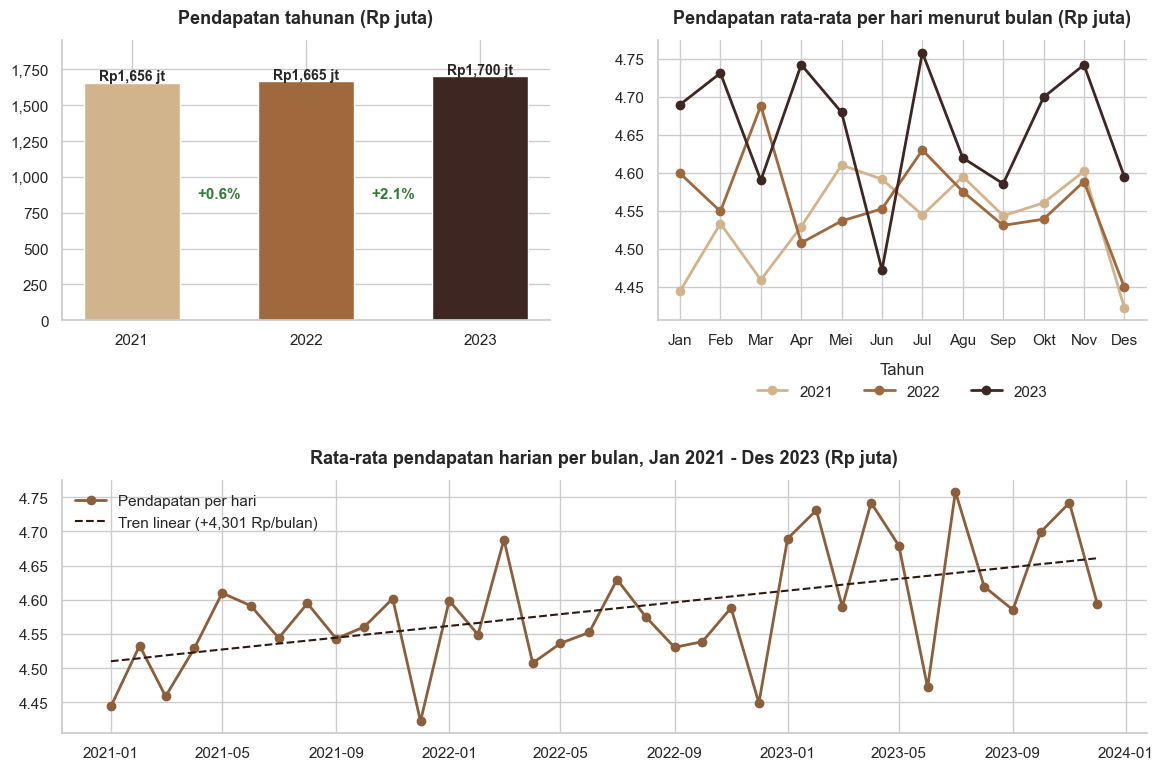

In [30]:
# Visual 1 - Tren penjualan tahunan dan bulanan
fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.9], hspace=0.6, wspace=0.22)
ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])

# (a) Pendapatan tahunan
bars = ax1.bar(tahunan.index.astype(str), tahunan["Pendapatan"], color=[WARNA_TAHUN[t] for t in tahunan.index], width=0.55)
for b, v in zip(bars, tahunan["Pendapatan"]):
    ax1.text(b.get_x() + b.get_width() / 2, v * 1.01, f"Rp{v/1e6:,.0f} jt", ha="center", fontsize=10, fontweight="bold")
for i in (1, 2):
    g = (tahunan["Pendapatan"].iloc[i] / tahunan["Pendapatan"].iloc[i - 1] - 1) * 100
    ax1.text(i - 0.5, tahunan["Pendapatan"].max() * 0.5, f"{g:+.1f}%", ha="center", fontsize=11, color="#2E7D32", fontweight="bold")
ax1.set_ylim(0, tahunan["Pendapatan"].max() * 1.15)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_juta))
ax1.set_title("Pendapatan tahunan (Rp juta)")

# (b) Pola bulanan per tahun
for t, g in bulanan.groupby("Tahun"):
    ax2.plot(g["Bulan_Num"], g["Pendapatan_Per_Hari"], marker="o", lw=2, color=WARNA_TAHUN[t], label=str(t))
ax2.set_xticks(range(1, 13)); ax2.set_xticklabels(BULAN_SINGKAT)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1e6:.2f}"))
ax2.set_title("Pendapatan rata-rata per hari menurut bulan (Rp juta)")
ax2.legend(title="Tahun", frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))

# (c) Timeline 36 bulan + garis tren
ax3.plot(ts.index, ts["Pendapatan_Per_Hari"], marker="o", color="#8B5E3C", lw=2, label="Pendapatan per hari")
ax3.plot(ts.index, reg_rp.intercept + reg_rp.slope * x, "--", color="#2E1A12", lw=1.5, label=f"Tren linear ({reg_rp.slope:+,.0f} Rp/bulan)")
ax3.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1e6:.2f}"))
ax3.set_title("Rata-rata pendapatan harian per bulan, Jan 2021 - Des 2023 (Rp juta)")
ax3.legend(frameon=False, loc="upper left")
plt.savefig("../images/01_tren_penjualan.png", dpi=150, bbox_inches="tight")
plt.show()

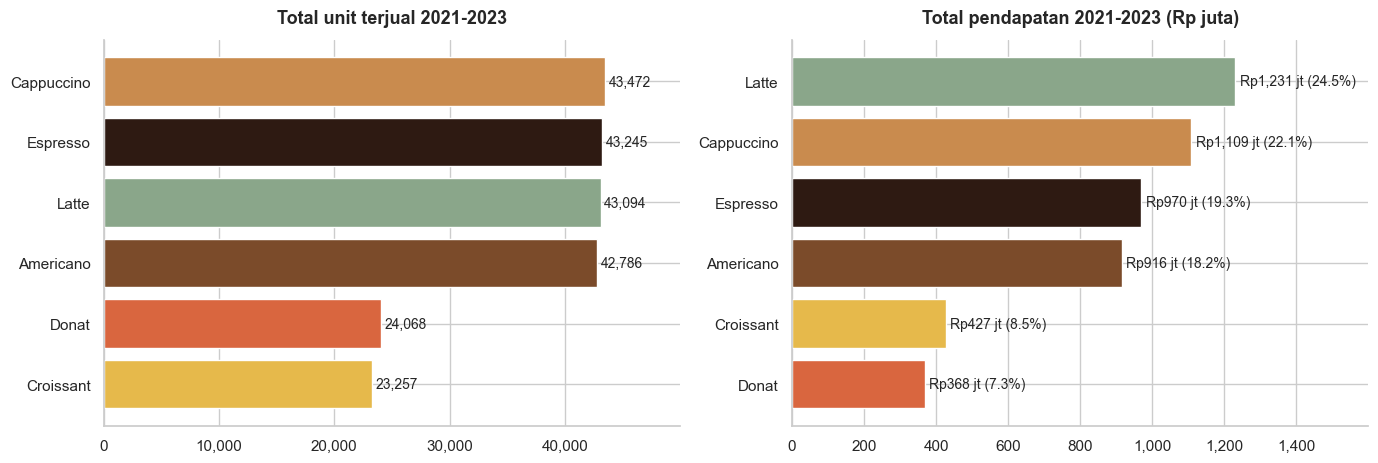

In [31]:
# Visual 2 - Produk terlaris
urut = ringkas.sort_values("Total_Unit")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].barh(urut.index, urut["Total_Unit"], color=[WARNA_PRODUK[p] for p in urut.index])
for i, v in enumerate(urut["Total_Unit"]):
    axes[0].text(v + 300, i, f"{v:,.0f}", va="center", fontsize=10)
axes[0].set_xlim(0, urut["Total_Unit"].max() * 1.15)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v:,.0f}"))
axes[0].set_title("Total unit terjual 2021-2023")

urut_rp = ringkas.sort_values("Total_Pendapatan")
axes[1].barh(urut_rp.index, urut_rp["Total_Pendapatan"], color=[WARNA_PRODUK[p] for p in urut_rp.index])
for i, (v, s) in enumerate(zip(urut_rp["Total_Pendapatan"], urut_rp["Porsi_Pendapatan_%"])):
    axes[1].text(v + 1.2e7, i, f"Rp{v/1e6:,.0f} jt ({s:.1f}%)", va="center", fontsize=10)
axes[1].set_xlim(0, urut_rp["Total_Pendapatan"].max() * 1.3)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(fmt_juta))
axes[1].set_title("Total pendapatan 2021-2023 (Rp juta)")
plt.tight_layout()
plt.savefig("../images/02_produk_terlaris.png", dpi=150, bbox_inches="tight")
plt.show()

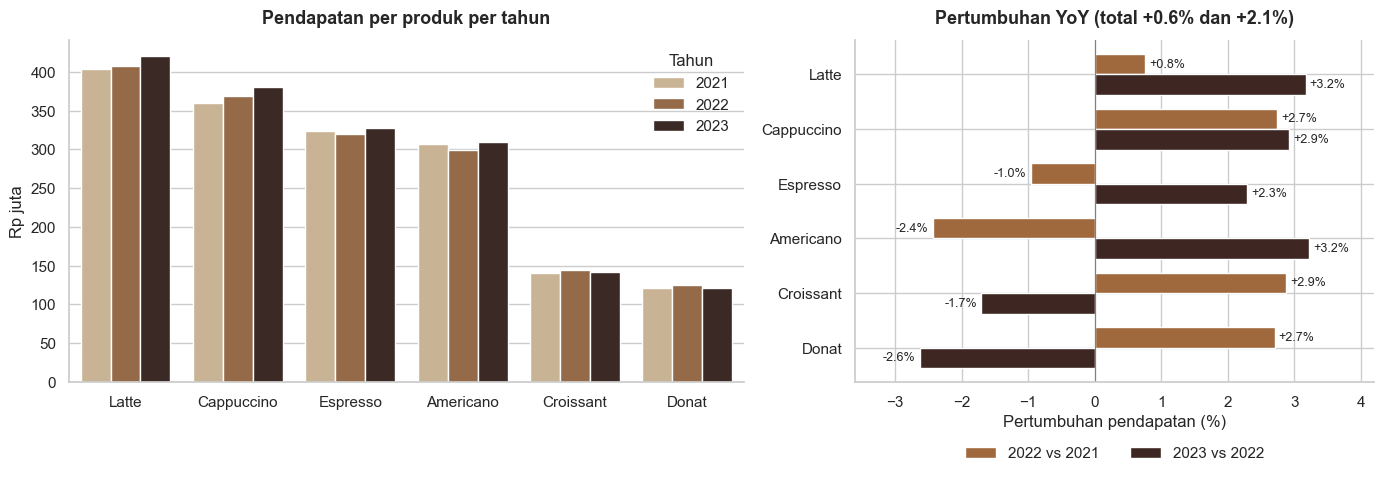

In [32]:
# Visual 3 - Pertumbuhan pendapatan
rev_produk = rev.drop("TOTAL")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})

urutan = rev_produk[2023].sort_values(ascending=False).index
long = rev_produk.loc[urutan].reset_index().melt(id_vars="Produk", var_name="Tahun", value_name="Pendapatan")
sns.barplot(data=long, x="Produk", y="Pendapatan", hue="Tahun", palette=WARNA_TAHUN, ax=axes[0])
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_juta))
axes[0].set_ylabel("Rp juta"); axes[0].set_xlabel("")
axes[0].set_title("Pendapatan per produk per tahun")
axes[0].legend(title="Tahun", frameon=False)

g = produk_saja[["Pendapatan_22_vs_21_%", "Pendapatan_23_vs_22_%"]].loc[urutan]
g.columns = ["2022 vs 2021", "2023 vs 2022"]
g.plot(kind="barh", ax=axes[1], color=["#A0693D", "#3E2723"], width=0.75)
axes[1].axvline(0, color="grey", lw=0.8)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%+.1f%%", padding=3, fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlabel("Pertumbuhan pendapatan (%)"); axes[1].set_ylabel("")
axes[1].set_title(f"Pertumbuhan YoY (total {pertumbuhan.loc['TOTAL','Pendapatan_22_vs_21_%']:+.1f}% dan {pertumbuhan.loc['TOTAL','Pendapatan_23_vs_22_%']:+.1f}%)")
axes[1].set_xlim(-3.6, 4.2)
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
plt.savefig("../images/03_pertumbuhan_pendapatan.png", dpi=150, bbox_inches="tight")
plt.show()

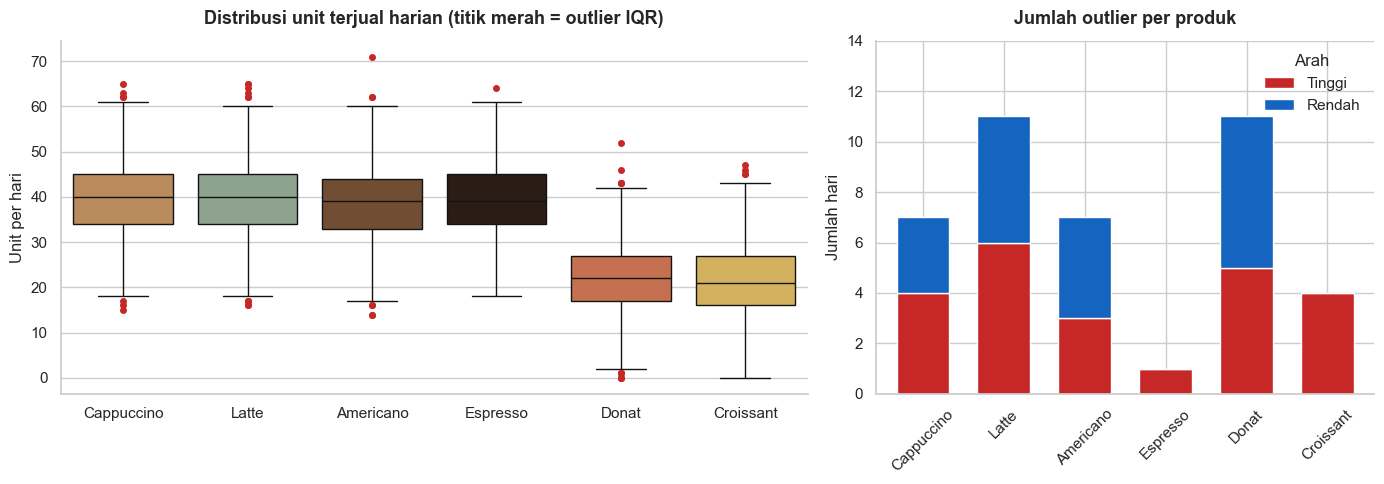

In [33]:
# Visual 4 - Distribusi penjualan dan outlier
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.5, 1]})

urut_med = obs.groupby("Produk")["Unit_Terjual"].median().sort_values(ascending=False).index
sns.boxplot(data=obs, x="Produk", y="Unit_Terjual", order=urut_med, palette=WARNA_PRODUK, ax=axes[0],
            flierprops=dict(marker="o", markerfacecolor="#C62828", markeredgecolor="#C62828", markersize=4))
axes[0].set_title("Distribusi unit terjual harian (titik merah = outlier IQR)")
axes[0].set_xlabel(""); axes[0].set_ylabel("Unit per hari")

o = ringkas_outlier[["Tinggi", "Rendah"]].loc[urut_med]
o.plot(kind="bar", stacked=True, ax=axes[1], color=["#C62828", "#1565C0"], width=0.65)
axes[1].set_title("Jumlah outlier per produk")
axes[1].set_xlabel(""); axes[1].set_ylabel("Jumlah hari")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, 14)
axes[1].legend(title="Arah", frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig("../images/04_distribusi_outlier.png", dpi=150, bbox_inches="tight")
plt.show()

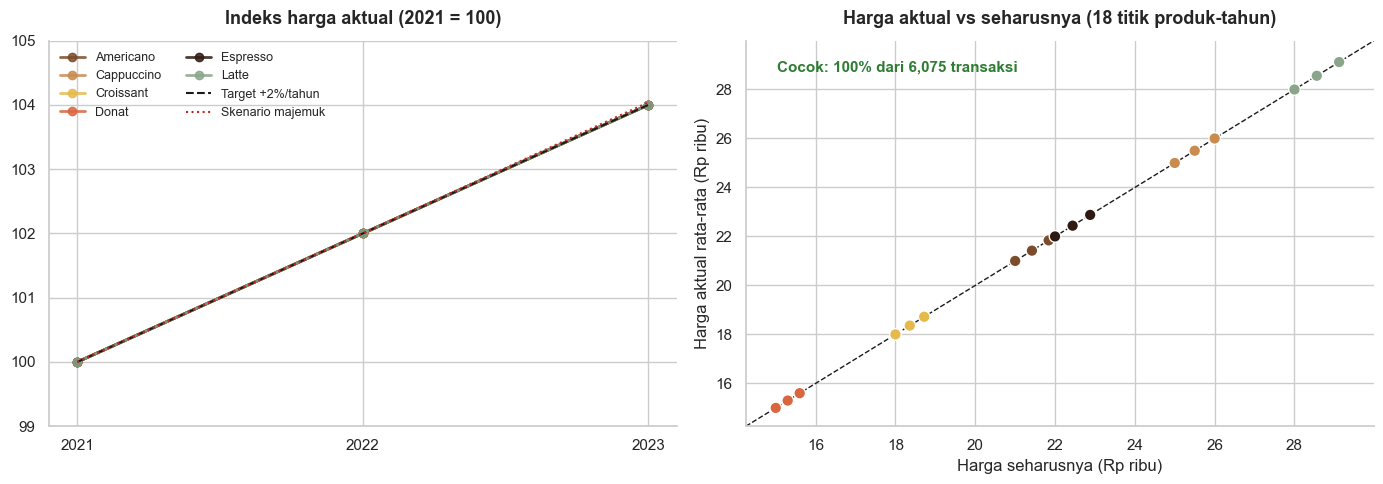

In [34]:
# Visual 5 - Konsistensi harga
rata_harga = df_clean[~df_clean["Harga_Imputasi"]].groupby(["Produk", "Tahun"])["Harga_Per_Unit"].mean().reset_index()
rata_harga = rata_harga.merge(ref_long, on=["Produk", "Tahun"])
rata_harga["Indeks"] = rata_harga["Harga_Per_Unit"] / rata_harga["Produk"].map(harga_dasar) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for p, g in rata_harga.groupby("Produk"):
    axes[0].plot(g["Tahun"], g["Indeks"], marker="o", lw=2, color=WARNA_PRODUK[p], label=p, alpha=0.85)
axes[0].plot([2021, 2022, 2023], [100, 102, 104], "k--", lw=1.5, label="Target +2%/tahun")
axes[0].plot([2021, 2022, 2023], [100, 102, 104.04], ":", color="#C62828", lw=1.5, label="Skenario majemuk")
axes[0].set_xticks([2021, 2022, 2023]); axes[0].set_ylim(99, 105)
axes[0].set_title("Indeks harga aktual (2021 = 100)")
axes[0].legend(frameon=False, fontsize=9, ncol=2)

axes[1].scatter(rata_harga["Harga_Seharusnya"], rata_harga["Harga_Per_Unit"], s=70,
                c=[WARNA_PRODUK[p] for p in rata_harga["Produk"]], edgecolor="white", zorder=3)
lim = [rata_harga["Harga_Seharusnya"].min() * 0.95, rata_harga["Harga_Seharusnya"].max() * 1.03]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1e3:.0f}"))
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1e3:.0f}"))
axes[1].set_xlabel("Harga seharusnya (Rp ribu)"); axes[1].set_ylabel("Harga aktual rata-rata (Rp ribu)")
axes[1].set_title("Harga aktual vs seharusnya (18 titik produk-tahun)")
axes[1].text(0.05, 0.92, f"Cocok: {cek['Cocok_Linear'].mean():.0%} dari {len(cek):,} transaksi", transform=axes[1].transAxes, fontsize=11, color="#2E7D32", fontweight="bold")
plt.tight_layout()
plt.savefig("../images/05_konsistensi_harga.png", dpi=150, bbox_inches="tight")
plt.show()

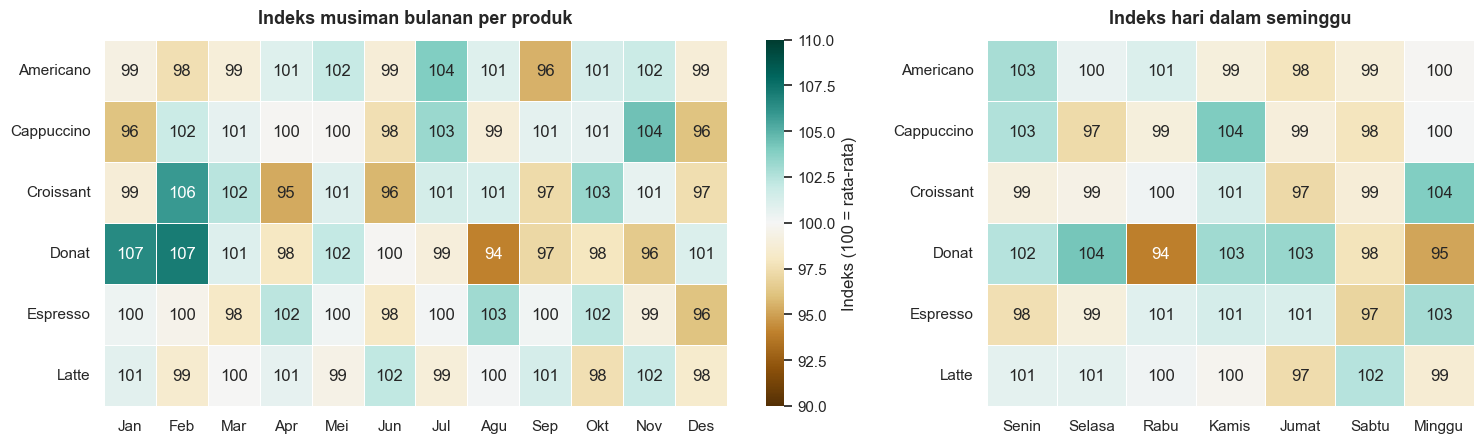

In [35]:
# Visual 6 - Pola musiman (bulan) dan hari dalam seminggu
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(idx_bulan, annot=True, fmt=".0f", cmap="BrBG", center=100, vmin=90, vmax=110,
            linewidths=0.5, cbar_kws={"label": "Indeks (100 = rata-rata)"}, ax=axes[0])
axes[0].set_title("Indeks musiman bulanan per produk"); axes[0].set_xlabel(""); axes[0].set_ylabel("")

sns.heatmap(idx_hari, annot=True, fmt=".0f", cmap="BrBG", center=100, vmin=90, vmax=110,
            linewidths=0.5, cbar=False, ax=axes[1])
axes[1].set_title("Indeks hari dalam seminggu"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("../images/06_pola_musiman.png", dpi=150, bbox_inches="tight")
plt.show()

---
# 7️. Business Insights & Portfolio Finalization

In [36]:
# Ringkasan angka kunci untuk dirujuk di insight
kpi = {
    "Total pendapatan 2021-2023 (Rp)": ringkas["Total_Pendapatan"].sum(),
    "Total unit terjual": ringkas["Total_Unit"].sum(),
    "Pendapatan 2021 (Rp)": tahunan.loc[2021, "Pendapatan"],
    "Pendapatan 2022 (Rp)": tahunan.loc[2022, "Pendapatan"],
    "Pendapatan 2023 (Rp)": tahunan.loc[2023, "Pendapatan"],
    "Pertumbuhan 2022 (%)": pertumbuhan.loc["TOTAL", "Pendapatan_22_vs_21_%"],
    "Pertumbuhan 2023 (%)": pertumbuhan.loc["TOTAL", "Pendapatan_23_vs_22_%"],
    "Pertumbuhan unit 2021->2023 (%)": pertumbuhan.loc["TOTAL", "Unit_23_vs_21_%"],
    "Produk pendapatan tertinggi": ringkas["Total_Pendapatan"].idxmax(),
    "Produk unit tertinggi": ringkas["Total_Unit"].idxmax(),
    "Porsi 4 minuman kopi (% pendapatan)": ringkas.loc[["Americano", "Cappuccino", "Espresso", "Latte"], "Porsi_Pendapatan_%"].sum(),
    "Porsi 2 makanan (% pendapatan)": ringkas.loc[["Croissant", "Donat"], "Porsi_Pendapatan_%"].sum(),
    "Produk musiman signifikan": ", ".join(musiman.index[musiman["Musiman_Signifikan"] == "Ya"]) or "Tidak ada",
}
pd.Series(kpi, name="Nilai").to_frame()

,Nilai
Total pendapatan 2021-2023 (Rp),"5,021,018,520.00"
Total unit terjual,219922
Pendapatan 2021 (Rp),"1,655,567,000.00"
Pendapatan 2022 (Rp),"1,665,239,760.00"
Pendapatan 2023 (Rp),"1,700,211,760.00"
Pertumbuhan 2022 (%),0.58
Pertumbuhan 2023 (%),2.10
Pertumbuhan unit 2021->2023 (%),-1.53
Produk pendapatan tertinggi,Latte
Produk unit tertinggi,Cappuccino


In [37]:
# Skenario ilustratif untuk potensi pertumbuhan (asumsi sederhana, bukan prediksi)
KOPI = ["Americano", "Cappuccino", "Espresso", "Latte"]
MAKANAN = ["Croissant", "Donat"]

unit_kopi = ringkas.loc[KOPI, "Total_Unit"].sum()
unit_makanan = ringkas.loc[MAKANAN, "Total_Unit"].sum()
attach_rate = unit_makanan / unit_kopi
harga_makanan = ringkas.loc[MAKANAN, "Total_Pendapatan"].sum() / unit_makanan

target_attach = 0.35
tambahan_unit = (target_attach - attach_rate) * unit_kopi
tambahan_rp_per_tahun = tambahan_unit * harga_makanan / 3

rp_per_unit_2023 = tahunan.loc[2023, "Pendapatan"] / tahunan.loc[2023, "Unit"]
pulih_unit = tahunan.loc[2021, "Unit"] - tahunan.loc[2023, "Unit"]

print(f"Makanan terjual per 100 unit kopi (attach rate) : {attach_rate:.1%}")
print(f"Harga rata-rata makanan                         : Rp{harga_makanan:,.0f}")
print(f"Skenario A - attach rate naik ke {target_attach:.0%}:")
print(f"   tambahan makanan  : {tambahan_unit:,.0f} unit selama 3 tahun")
print(f"   tambahan pendapatan: Rp{tambahan_rp_per_tahun/1e6:,.0f} juta per tahun ({tambahan_rp_per_tahun / tahunan.loc[2023, 'Pendapatan']:.1%} dari pendapatan 2023)")
print(f"Skenario B - volume 2023 kembali ke level 2021:")
print(f"   tambahan unit     : {pulih_unit:,.0f} per tahun")
print(f"   tambahan pendapatan: Rp{pulih_unit * rp_per_unit_2023/1e6:,.0f} juta per tahun ({pulih_unit * rp_per_unit_2023 / tahunan.loc[2023, 'Pendapatan']:.1%})")
print(f"Porsi Latte + Cappuccino dalam pendapatan       : {ringkas.loc[['Latte', 'Cappuccino'], 'Porsi_Pendapatan_%'].sum():.1f}%")
print(f"Perubahan unit tahunan: 2022 {pertumbuhan.loc['TOTAL','Unit_22_vs_21_%']:+.1f}%, 2023 {pertumbuhan.loc['TOTAL','Unit_23_vs_22_%']:+.1f}%")

Makanan terjual per 100 unit kopi (attach rate) : 27.4%
Harga rata-rata makanan                         : Rp16,800
Skenario A - attach rate naik ke 35%:
   tambahan makanan  : 13,084 unit selama 3 tahun
   tambahan pendapatan: Rp73 juta per tahun (4.3% dari pendapatan 2023)
Skenario B - volume 2023 kembali ke level 2021:
   tambahan unit     : 1,134 per tahun
   tambahan pendapatan: Rp26 juta per tahun (1.6%)
Porsi Latte + Cappuccino dalam pendapatan       : 46.6%
Perubahan unit tahunan: 2022 -1.4%, 2023 -0.2%


## Insight Utama

**1. Pertumbuhan pendapatan datar, dan seluruhnya berasal dari harga, bukan volume.**
Pendapatan naik dari Rp1,656 miliar (2021) menjadi Rp1,700 miliar (2023), hanya **+0,6%** lalu **+2,1%** (total +2,7%). Namun unit terjual justru turun dari 74.022 menjadi 72.888 (**-1,5%**). Kenaikan harga 2% per tahun menutup penurunan volume. Kabar baiknya, penurunan melambat dari -1,4% (2022) menjadi -0,2% (2023). Tren pendapatan harian memang naik secara statistik (p = 0,001), tetapi unit per hari turun (p = 0,012). Itu mengonfirmasi bahwa kenaikan berasal dari harga.

**2. Latte adalah mesin pendapatan, Cappuccino adalah mesin volume.**
Latte menyumbang **24,5%** pendapatan (Rp1,23 miliar) walau unitnya urutan ketiga, karena harganya tertinggi (Rp28 ribu pada 2021). Cappuccino memimpin unit (43.472) dan punya pertumbuhan pendapatan tertinggi, **+5,8%** sejak 2021, serta menjadi produk terlaris sejak 2022. Keduanya menyumbang **46,6%** pendapatan.

**3. Empat minuman kopi menopang bisnis; makanan masih lemah.**
Kopi menyumbang **84,2%** pendapatan. Croissant dan Donat hanya 15,8% pendapatan, dan Donat paling stagnan: pendapatan **0,0%** dan unit **-3,8%** sejak 2021. Rata-rata hanya 27 makanan terjual untuk setiap 100 kopi.

**4. Permintaan sangat stabil dan tidak musiman.**
Uji ANOVA tidak menemukan musiman yang signifikan pada satu pun produk (p = 0,19 sampai 0,94). Puncak yang tampak, misalnya Donat di Januari-Februari atau Cappuccino di November, tidak konsisten antar tahun (korelasi pola bulanan antar tahun hanya 0,02 sampai 0,41), sehingga kemungkinan besar noise. Efek hari dalam seminggu pun lemah. Hanya Cappuccino yang p-value-nya di bawah 0,05 (0,04), dan itu satu dari enam uji, jadi belum layak dijadikan dasar keputusan.

**5. Data penjualan relatif bersih dari anomali.**
Hanya **41 dari 6.074 hari-produk (0,68%)** yang menjadi outlier IQR, tersebar merata tanpa klaster waktu. Outlier paling ekstrem adalah Americano 71 unit pada 28 April 2022 (Z = 3,95). Beberapa hari Croissant dan Donat tercatat 0 unit, kemungkinan stok habis atau tidak diproduksi.

**6. Kebijakan harga konsisten.**
100% harga tercatat (6.075 transaksi) sesuai harga dasar 2021 yang dinaikkan 2% setiap tahun dari harga dasar (linear), bukan majemuk.

---

## Rekomendasi Strategi

| Prioritas | Rekomendasi | Dasar data |
|---|---|---|
| 1 | **Bundling kopi + makanan** (paket sarapan atau sore), target 35 makanan per 100 kopi | Rasio sekarang 27,4%; skenario ilustratif +Rp73 juta/tahun (+4,3%) |
| 2 | **Jadikan Latte dan Cappuccino produk andalan**: promosi, upsell ukuran/varian rasa, posisi menu utama | 46,6% pendapatan; Cappuccino tumbuh paling cepat |
| 3 | **Hentikan penurunan volume** dengan program loyalitas atau promo jam sepi, jangan hanya mengandalkan kenaikan harga | Unit -1,5% dalam 2 tahun; menutup selisih ke level 2021 ≈ +Rp26 juta/tahun |
| 4 | **Evaluasi Donat**: variasi rasa baru, rotasi menu, atau jadikan pendamping paket | Pendapatan stagnan, unit -3,8% |
| 5 | **Rencanakan stok dan jadwal tanpa asumsi musiman**; gunakan pola harian yang stabil (±33 unit per produk per hari) dan hanya buat promo musiman sebagai eksperimen yang diukur | Tidak ada musiman signifikan |
| 6 | **Perbaiki pencatatan**: validasi input, hindari baris ganda, catat stok habis, tambahkan biaya/margin | ±7,6% sel kosong dan 19 duplikat di data mentah |

## Potensi Pertumbuhan
- **Cross-sell makanan** adalah peluang terbesar yang terlihat di data: attach rate 27,4% naik ke 35% menambah sekitar **Rp73 juta per tahun**.
- **Kenaikan harga lanjutan** masih bisa dilakukan karena volume relatif stabil (-0,2% pada 2023, meski harga naik), tetapi sebaiknya diuji bertahap per produk. Latte dan Cappuccino adalah kandidat terbaik karena permintaannya paling kuat.
- **Pemulihan volume** ke level 2021 menambah sekitar Rp26 juta per tahun, sehingga manfaatnya lebih kecil daripada cross-sell.

## Kesimpulan
Kopi Nangkau adalah bisnis yang **stabil tetapi stagnan**. Permintaan datar sepanjang tahun, produk andalan jelas (Latte dan Cappuccino), dan kebijakan harga disiplin. Pertumbuhan masa depan kemungkinan tidak datang dari kenaikan harga tahunan saja, melainkan dari **menambah nilai tiap pelanggan** lewat bundling makanan dan menjaga volume.

## Keterbatasan
- **7,5% unit diimputasi** dengan median produk-tahun-bulan (7,8% dari pendapatan). Angka total bergantung pada asumsi ini, tetapi imputasi tidak membentuk pola musiman karena analisis musiman dan outlier memakai data asli.
- Penempatan baris tanpa produk ke "slot kosong" mengasumsikan setiap produk terjual setiap hari. Hanya 1 baris yang tidak bisa dipakai dan dibuang.
- Data tidak memuat **biaya, margin, jumlah pelanggan, promo, atau cuaca**, jadi "produk terbaik" di sini berarti terbaik dalam pendapatan, bukan laba.
- Hanya 3 tahun data, sehingga musiman yang sangat lemah sulit dibedakan dari noise.
- Skenario pertumbuhan bersifat ilustratif, bukan prediksi.

In [38]:
# Simpan dataset bersih untuk reproduksibilitas
df_clean.to_csv("../data/penjualan_kopi_bersih.csv", index=False)
print(f"Dataset bersih disimpan: {df_clean.shape[0]:,} baris x {df_clean.shape[1]} kolom")

Dataset bersih disimpan: 6,570 baris x 12 kolom
